# TP7 — Prévision Multivariée Multi-Step avec LSTM et BiLSTM
---

## Imports et configuration

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error
from statsmodels.tsa.seasonal import seasonal_decompose
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

---
## Q1 — Chargement du dataset, préparation de l'index temporel et sélection des variables d'entrée

In [2]:
# 1) CHARGEMENT DES DONNÉES
url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip'
zip_path = tf.keras.utils.get_file('jena_climate_2009_2016.csv.zip', origin=url, extract=False)

extract_dir = os.path.dirname(zip_path)
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

csv_path = os.path.join(extract_dir, 'jena_climate_2009_2016.csv')
df = pd.read_csv(csv_path)
print('Taille initiale :', df.shape)
print(df.head())

Taille initiale : (420551, 15)
             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0 

In [3]:
#  PRÉPARATION DE LA COLONNE DATE
df['Date Time'] = pd.to_datetime(df['Date Time'], format='%d.%m.%Y %H:%M:%S')
df.set_index('Date Time', inplace=True)
print('\nTypes de données :')
print(df.dtypes)


Types de données :
p (mbar)           float64
T (degC)           float64
Tpot (K)           float64
Tdew (degC)        float64
rh (%)             float64
VPmax (mbar)       float64
VPact (mbar)       float64
VPdef (mbar)       float64
sh (g/kg)          float64
H2OC (mmol/mol)    float64
rho (g/m**3)       float64
wv (m/s)           float64
max. wv (m/s)      float64
wd (deg)           float64
dtype: object


In [4]:
# SÉLECTION DES VARIABLES D'ENTRÉE
feature_cols = [
    'T (degC)',        # Température
    'rh (%)',          # Humidité relative
    'p (mbar)',        # Pression
    'wv (m/s)',        # Vitesse du vent
    'max. wv (m/s)',   # Vitesse maximale du vent
    'wd (deg)'         # Direction du vent
]

data = df[feature_cols].copy()
print('Taille du dataset global :', df.shape)
print('Taille du sous-dataset  :', data.shape)
print('Variables sélectionnées :', feature_cols)

Taille du dataset global : (420551, 14)
Taille du sous-dataset  : (420551, 6)
Variables sélectionnées : ['T (degC)', 'rh (%)', 'p (mbar)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)']


---
## Q2 — Rééchantillonnage horaire et définition des variables X et Y

In [5]:
# RÉÉCHANTILLONNAGE EN FRÉQUENCE HORAIRE
data_hourly = data.resample('1H').agg(['mean', 'max', 'min'])
print("\nTaille après resampling horaire :", data_hourly.shape)
print(data_hourly.head())


Taille après resampling horaire : (70129, 18)
                     T (degC)                 rh (%)                p (mbar)  \
                         mean   max   min       mean   max   min        mean   
Date Time                                                                      
2009-01-01 00:00:00 -8.304000 -8.02 -8.51  93.780000  94.2  93.3  996.528000   
2009-01-01 01:00:00 -8.065000 -7.62 -8.76  93.933333  94.8  93.1  996.525000   
2009-01-01 02:00:00 -8.763333 -8.66 -8.88  93.533333  93.9  93.2  996.745000   
2009-01-01 03:00:00 -8.896667 -8.81 -8.99  93.200000  93.5  92.4  996.986667   
2009-01-01 04:00:00 -9.348333 -9.05 -9.50  92.383333  92.8  92.0  997.158333   

                                     wv (m/s)             max. wv (m/s)        \
                        max     min      mean   max   min          mean   max   
Date Time                                                                       
2009-01-01 00:00:00  996.57  996.51  0.520000  1.03  0.19      1.0020

/tmp/ipykernel_27430/1962593078.py:2: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  data_hourly = data.resample('1H').agg(['mean', 'max', 'min'])


In [6]:
# DÉFINITION DES VARIABLES CIBLES Y
data_hourly.columns = ['_'.join(col) for col in data_hourly.columns]
feature_cols = data_hourly.columns.tolist()
target_cols = [
    "T (degC)_mean",
    "rh (%)_mean",
    "p (mbar)_mean"
]
X = data_hourly[feature_cols]
y = data_hourly[target_cols]

print("Shape X :", X.shape)
print("Shape y :", y.shape)

Shape X : (70129, 18)
Shape y : (70129, 3)


---
## Q3 — Vérification et traitement des valeurs manquantes

In [7]:
# VÉRIFICATION DES VALEURS MANQUANTES
print('Valeurs manquantes avant traitement :')
print(data_hourly.isnull().sum())
data_hourly = data_hourly.interpolate(method='time').dropna()

# Reconstituer X et y après nettoyage
X = data_hourly[feature_cols]
y = data_hourly[target_cols]

print('\nTaille après interpolation :', data_hourly.shape)
print('Nombre de NaN restants :')
print(data_hourly.isnull().sum())

Valeurs manquantes avant traitement :
T (degC)_mean         88
T (degC)_max          88
T (degC)_min          88
rh (%)_mean           88
rh (%)_max            88
rh (%)_min            88
p (mbar)_mean         88
p (mbar)_max          88
p (mbar)_min          88
wv (m/s)_mean         88
wv (m/s)_max          88
wv (m/s)_min          88
max. wv (m/s)_mean    88
max. wv (m/s)_max     88
max. wv (m/s)_min     88
wd (deg)_mean         88
wd (deg)_max          88
wd (deg)_min          88
dtype: int64

Taille après interpolation : (70129, 18)
Nombre de NaN restants :
T (degC)_mean         0
T (degC)_max          0
T (degC)_min          0
rh (%)_mean           0
rh (%)_max            0
rh (%)_min            0
p (mbar)_mean         0
p (mbar)_max          0
p (mbar)_min          0
wv (m/s)_mean         0
wv (m/s)_max          0
wv (m/s)_min          0
max. wv (m/s)_mean    0
max. wv (m/s)_max     0
max. wv (m/s)_min     0
wd (deg)_mean         0
wd (deg)_max          0
wd (deg)_min          0


---
## Q4 — Découpage Train / Validation / Test (ordre temporel respecté)

In [8]:
# DÉCOUPAGE TRAIN / VALIDATION / TEST
n = len(X)

train_size = int(n * 0.70)
val_size   = int(n * 0.15)
test_size  = n - train_size - val_size

X_train_df = X.iloc[:train_size]
X_val_df   = X.iloc[train_size : train_size + val_size]
X_test_df  = X.iloc[train_size + val_size :]

y_train_df = y.iloc[:train_size]
y_val_df   = y.iloc[train_size : train_size + val_size]
y_test_df  = y.iloc[train_size + val_size :]

print('Shape X_train :', X_train_df.shape)
print('Shape X_val   :', X_val_df.shape)
print('Shape X_test  :', X_test_df.shape)
print('Shape y_train :', y_train_df.shape)
print('Shape y_val   :', y_val_df.shape)
print('Shape y_test  :', y_test_df.shape)

Shape X_train : (49090, 18)
Shape X_val   : (10519, 18)
Shape X_test  : (10520, 18)
Shape y_train : (49090, 3)
Shape y_val   : (10519, 3)
Shape y_test  : (10520, 3)


---
## Q5 — Normalisation séparée des variables X et Y

In [9]:
# NORMALISATION
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train_df)
X_val_scaled   = scaler_X.transform(X_val_df)
X_test_scaled  = scaler_X.transform(X_test_df)

y_train_scaled = scaler_y.fit_transform(y_train_df)
y_val_scaled   = scaler_y.transform(y_val_df)
y_test_scaled  = scaler_y.transform(y_test_df)

print('Shape X_train_scaled :', X_train_scaled.shape)
print('Shape y_train_scaled :', y_train_scaled.shape)

Shape X_train_scaled : (49090, 18)
Shape y_train_scaled : (49090, 3)


---
## Q6 — Création des séquences temporelles multivariées (lookback=72, horizon=12)

In [10]:
# HYPERPARAMÈTRES TEMPORELS
lookback = 72   # 72 heures passées = 3 cycles journaliers
horizon  = 12   # Prédire les 12 prochaines heures

def create_multivariate_sequences(X_data, y_data, lookback, horizon):
    """
    Crée des séquences glissantes pour LSTM multivarié multi-step.
    X_window : (lookback, n_features)
    y_window : (horizon, n_targets)
    """
    X_seq, y_seq = [], []
    for i in range(len(X_data) - lookback - horizon + 1):
        X_window = X_data[i : i + lookback]              # fenêtre d'entrée
        y_window = y_data[i + lookback : i + lookback + horizon]  # fenêtre cible
        X_seq.append(X_window)
        y_seq.append(y_window)
    return np.array(X_seq), np.array(y_seq)

X_train, y_train = create_multivariate_sequences(X_train_scaled, y_train_scaled, lookback, horizon)
X_val,   y_val   = create_multivariate_sequences(X_val_scaled,   y_val_scaled,   lookback, horizon)
X_test,  y_test  = create_multivariate_sequences(X_test_scaled,  y_test_scaled,  lookback, horizon)

print('Shape X_train :', X_train.shape)
print('Shape y_train :', y_train.shape)
print('Shape X_val   :', X_val.shape)
print('Shape y_val   :', y_val.shape)
print('Shape X_test  :', X_test.shape)
print('Shape y_test  :', y_test.shape)

Shape X_train : (49007, 72, 18)
Shape y_train : (49007, 12, 3)
Shape X_val   : (10436, 72, 18)
Shape y_val   : (10436, 12, 3)
Shape X_test  : (10437, 72, 18)
Shape y_test  : (10437, 12, 3)


---
## Q7 — Affichage et interprétation des dimensions

In [11]:
print(f'X_train : {X_train.shape}')
print(f'  → {X_train.shape[0]} séquences d\'entraînement')
print(f'  → {X_train.shape[1]} pas de temps (lookback = 72h = 3 jours)')
print(f'  → {X_train.shape[2]} variables d\'entrée (features)')
print()
print(f'y_train : {y_train.shape}')
print(f'  → {y_train.shape[0]} séquences cibles')
print(f'  → {y_train.shape[1]} pas de temps futurs (horizon = 12h)')
print(f'  → {y_train.shape[2]} variables cibles (T, rh, p)')


X_train : (49007, 72, 18)
  → 49007 séquences d'entraînement
  → 72 pas de temps (lookback = 72h = 3 jours)
  → 18 variables d'entrée (features)

y_train : (49007, 12, 3)
  → 49007 séquences cibles
  → 12 pas de temps futurs (horizon = 12h)
  → 3 variables cibles (T, rh, p)


---
## Q8 — Adaptation de la sortie Y pour la couche Dense (aplatissement)


In [12]:
# APLATISSEMENT DE LA SORTIE
n_features = X_train.shape[2]
n_targets  = y_train.shape[2]

# y : (n_samples, horizon, n_targets) → (n_samples, horizon * n_targets)
y_train_flat = y_train.reshape((y_train.shape[0], horizon * n_targets))
y_val_flat   = y_val.reshape((y_val.shape[0],   horizon * n_targets))
y_test_flat  = y_test.reshape((y_test.shape[0],  horizon * n_targets))

print('Shape y_train_flat :', y_train_flat.shape)  # (n, 36)
print('Shape y_val_flat   :', y_val_flat.shape)
print('Shape y_test_flat  :', y_test_flat.shape)

Shape y_train_flat : (49007, 36)
Shape y_val_flat   : (10436, 36)
Shape y_test_flat  : (10437, 36)


---
## Q9 — Construction, compilation et entraînement des modèles LSTM et BiLSTM

In [13]:
# CONSTRUCTION DES MODÈLES

def build_lstm_model(lookback, n_features, horizon, n_targets):
    model = Sequential([
        LSTM(64, input_shape=(lookback, n_features)),
        Dense(horizon * n_targets)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

def build_bilstm_model(lookback, n_features, horizon, n_targets):
    model = Sequential([
        Bidirectional(LSTM(64), input_shape=(lookback, n_features)),
        Dense(horizon * n_targets)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

lstm_model   = build_lstm_model(lookback, n_features, horizon, n_targets)
bilstm_model = build_bilstm_model(lookback, n_features, horizon, n_targets)

print('\nRésumé modèle LSTM :')
lstm_model.summary()
print('\nRésumé modèle BiLSTM :')
bilstm_model.summary()


Résumé modèle LSTM :


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        21,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,588 (92.14 KB)

 Trainable params: 23,588 (92.14 KB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 128)            │        42,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,140 (184.14 KB)

 Trainable params: 47,140 (184.14 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# EARLY STOPPING — UN PAR MODÈLE
early_stop_lstm = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

early_stop_bilstm = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

#  ENTRAÎNEMENT LSTM

history_lstm = lstm_model.fit(
    X_train, y_train_flat,
    validation_data=(X_val, y_val_flat),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop_lstm],
    verbose=1
)

history_bilstm = bilstm_model.fit(
    X_train, y_train_flat,
    validation_data=(X_val, y_val_flat),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop_bilstm],
    verbose=1
)

Epoch 1/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 37s 46ms/step - loss: 0.0160 - val_loss: 0.0060
Epoch 2/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step - loss: 0.0049 - val_loss: 0.0056
Epoch 3/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 41s 42ms/step - loss: 0.0045 - val_loss: 0.0054
Epoch 4/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 42s 44ms/step - loss: 0.0043 - val_loss: 0.0052
Epoch 5/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - loss: 0.0042 - val_loss: 0.0049
Epoch 6/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - loss: 0.0041 - val_loss: 0.0048
Epoch 7/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 43s 47ms/step - loss: 0.0040 - val_loss: 0.0047
Epoch 8/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - loss: 0.0039 - val_loss: 0.0046
Epoch 9/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - loss: 0.0039 - val_loss: 0.0045
Epoch 10/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - loss: 0.0038 - val_loss: 0.0043
Epoch 11/30
766/766 ━━━━━━━━━━━━━━━━━━━━ 41s 43ms/step - loss: 0.0038 - val_loss: 0.0042
Epoch 12/30
766/766 ━━━━━━━━━━

---
## Q10 — Courbes d'apprentissage et interprétation

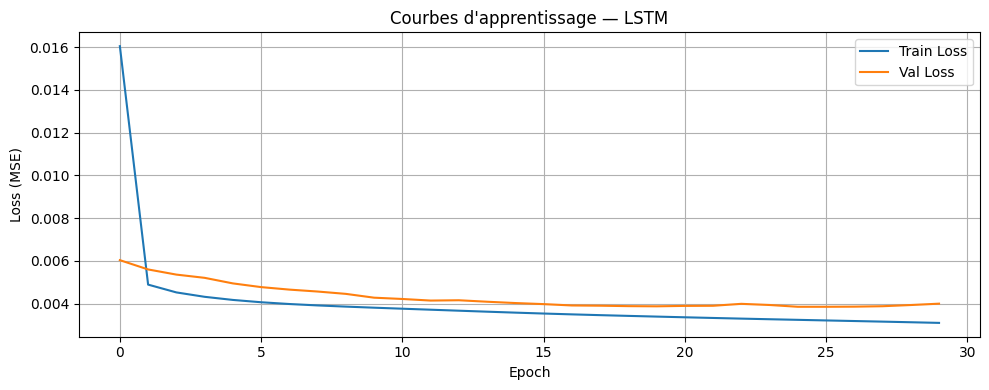

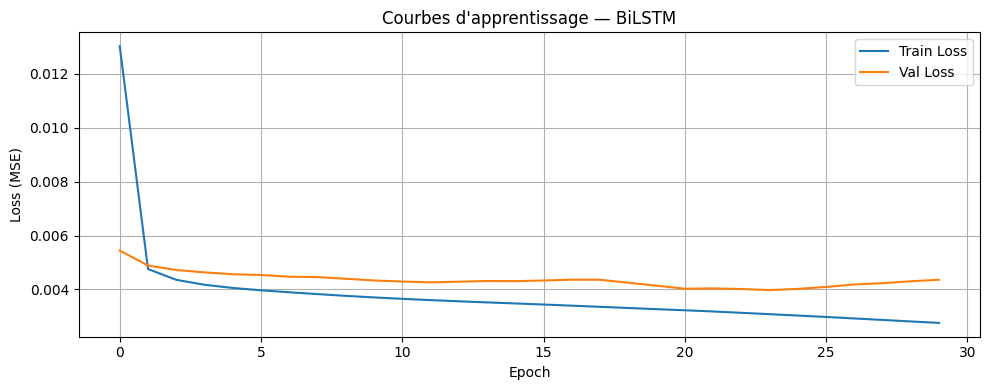

In [15]:
# COURBES D'APPRENTISSAGE
def plot_history(history, title):
    plt.figure(figsize=(10, 4))
    plt.plot(history.history['loss'],     label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

plot_history(history_lstm,   'Courbes d\'apprentissage — LSTM')
plot_history(history_bilstm, 'Courbes d\'apprentissage — BiLSTM')

**LSTM :**
- La `train_loss` et la `val_loss` descendent rapidement lors des premières époques.
- Les deux courbes convergent et restent proches → le modèle apprend sans sur-apprentissage notable.

**BiLSTM :**
- Comportement presque similaire, mais la convergence est légèrement plus lente (plus de paramètres à optimiser : 42 496 vs 21 248).
- La `val_loss` finale du LSYM reste meilleure que celle obtenue par le BiLSTM.Toutefois, les deux architectures capturent correctement les dépendances temporelles.

---
## Q11 — Prédictions sur le jeu de test et reshape multi-step / multivarié

In [16]:
# PRÉDICTIONS (sortie aplatie)
y_pred_lstm_flat   = lstm_model.predict(X_test)    # (n_test, 36)
y_pred_bilstm_flat = bilstm_model.predict(X_test)  # (n_test, 36)

print('Forme aplatie LSTM   :', y_pred_lstm_flat.shape)
print('Forme aplatie BiLSTM :', y_pred_bilstm_flat.shape)

# ── RESHAPE → structure multi-step et multivariée ─────────────────────────
y_pred_lstm   = y_pred_lstm_flat.reshape((-1, horizon, n_targets))    # (n, 12, 3)
y_pred_bilstm = y_pred_bilstm_flat.reshape((-1, horizon, n_targets))  # (n, 12, 3)

print('\nForme après reshape LSTM   :', y_pred_lstm.shape)
print('Forme après reshape BiLSTM :', y_pred_bilstm.shape)
print('Interprétation : (n_échantillons, 12 horizons, 3 variables cibles)')

327/327 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
327/327 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
Forme aplatie LSTM   : (10437, 36)
Forme aplatie BiLSTM : (10437, 36)

Forme après reshape LSTM   : (10437, 12, 3)
Forme après reshape BiLSTM : (10437, 12, 3)
Interprétation : (n_échantillons, 12 horizons, 3 variables cibles)


---
## Q12 — Inverse Scaling : retour à l'échelle originale

In [17]:
# ── INVERSE SCALING ────────────────────────────────────────────────────────
# Le scaler_y exige des données 2D : (n_samples, n_targets)
# On passe temporairement à (n_samples * horizon, n_targets)

def inverse_transform_multistep(y_scaled, scaler_y):
    s, h, t = y_scaled.shape                        # (n, 12, 3)
    y_2d    = y_scaled.reshape((s * h, t))          # (n*12, 3)
    y_inv_2d = scaler_y.inverse_transform(y_2d)     # (n*12, 3)
    y_inv    = y_inv_2d.reshape((s, h, t))          # (n, 12, 3)
    return y_inv

y_test_inv        = inverse_transform_multistep(y_test,        scaler_y)
y_pred_lstm_inv   = inverse_transform_multistep(y_pred_lstm,   scaler_y)
y_pred_bilstm_inv = inverse_transform_multistep(y_pred_bilstm, scaler_y)

print('Forme y_test_inv        :', y_test_inv.shape)        # (n, 12, 3)
print('Forme y_pred_lstm_inv   :', y_pred_lstm_inv.shape)
print('Forme y_pred_bilstm_inv :', y_pred_bilstm_inv.shape)
print('\nLes prédictions sont maintenant dans les unités réelles (°C, %, mbar)')

Forme y_test_inv        : (10437, 12, 3)
Forme y_pred_lstm_inv   : (10437, 12, 3)
Forme y_pred_bilstm_inv : (10437, 12, 3)

Les prédictions sont maintenant dans les unités réelles (°C, %, mbar)


---
## Q13 — Évaluation par horizon et par variable cible (MAE, RMSE, R²)

In [18]:
# ÉVALUATION MULTIVARIÉ MULTI-STEP
def evaluate_multivariate_multistep(y_true, y_pred, model_name, target_cols):
    results = []
    for h in range(y_true.shape[1]):          # pour chaque horizon
        for j in range(y_true.shape[2]):      # pour chaque variable cible
            true_hj = y_true[:, h, j]
            pred_hj = y_pred[:, h, j]
            mae  = mean_absolute_error(true_hj, pred_hj)
            rmse = np.sqrt(mean_squared_error(true_hj, pred_hj))
            r2   = r2_score(true_hj, pred_hj)
            results.append({
                'Model'   : model_name,
                'Horizon' : h + 1,
                'Variable': target_cols[j],
                'MAE'     : mae,
                'RMSE'    : rmse,
                'R2'      : r2
            })
    return pd.DataFrame(results)

df_lstm_scores   = evaluate_multivariate_multistep(y_test_inv, y_pred_lstm_inv,   'LSTM',   target_cols)
df_bilstm_scores = evaluate_multivariate_multistep(y_test_inv, y_pred_bilstm_inv, 'BiLSTM', target_cols)
df_scores        = pd.concat([df_lstm_scores, df_bilstm_scores], axis=0)

# TABLEAU COMPARATIF PIVOT
print('TABLEAU FINAL COMPARATIF (RMSE par Horizon et Variable) :')
pivot_rmse = df_scores.pivot_table(
    index=['Horizon', 'Variable'],
    columns='Model',
    values='RMSE'
)
print(pivot_rmse.round(4))

print('\nTableau MAE :')
pivot_mae = df_scores.pivot_table(
    index=['Horizon', 'Variable'],
    columns='Model',
    values='MAE'
)
print(pivot_mae.round(4))

TABLEAU FINAL COMPARATIF (RMSE par Horizon et Variable) :
Model                   BiLSTM     LSTM
Horizon Variable                       
1       T (degC)_mean   0.6783   0.5782
        p (mbar)_mean   0.4641   0.6122
        rh (%)_mean     2.8010   2.9095
2       T (degC)_mean   0.9819   0.9653
        p (mbar)_mean   0.6745   0.7918
        rh (%)_mean     4.6629   4.6684
3       T (degC)_mean   1.2797   1.2697
        p (mbar)_mean   0.8329   1.0501
        rh (%)_mean     5.9738   5.9528
4       T (degC)_mean   1.5138   1.5099
        p (mbar)_mean   1.0882   1.1490
        rh (%)_mean     6.9513   6.9124
5       T (degC)_mean   1.7251   1.7079
        p (mbar)_mean   1.3280   1.3799
        rh (%)_mean     7.7094   7.6603
6       T (degC)_mean   1.9005   1.8558
        p (mbar)_mean   1.5504   1.5529
        rh (%)_mean     8.2936   8.2001
7       T (degC)_mean   2.0409   2.0001
        p (mbar)_mean   1.8066   1.7794
        rh (%)_mean     8.7339   8.6376
8       T (degC)_mean 

---
## Q14 — Évolution des métriques en fonction de l'horizon

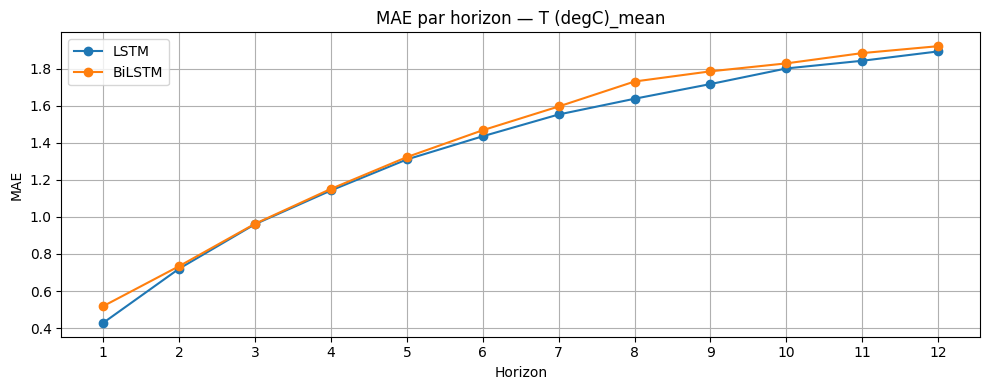

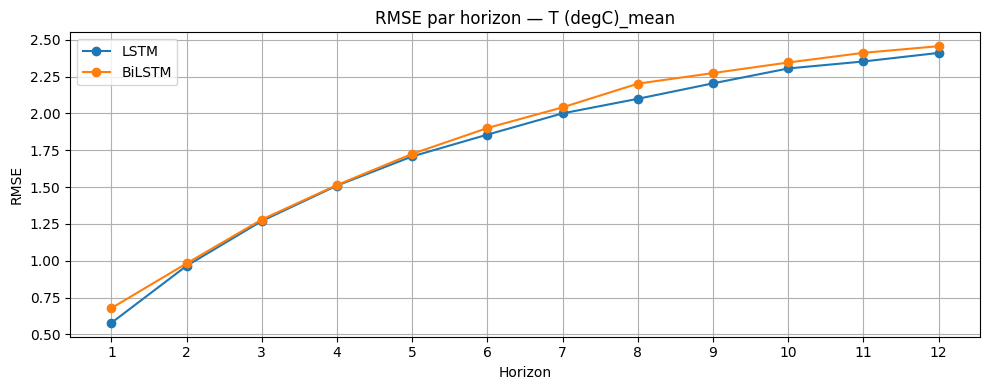

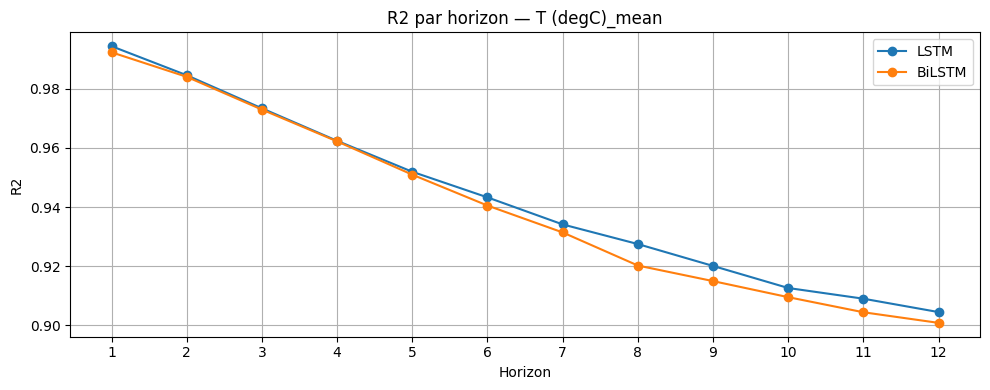

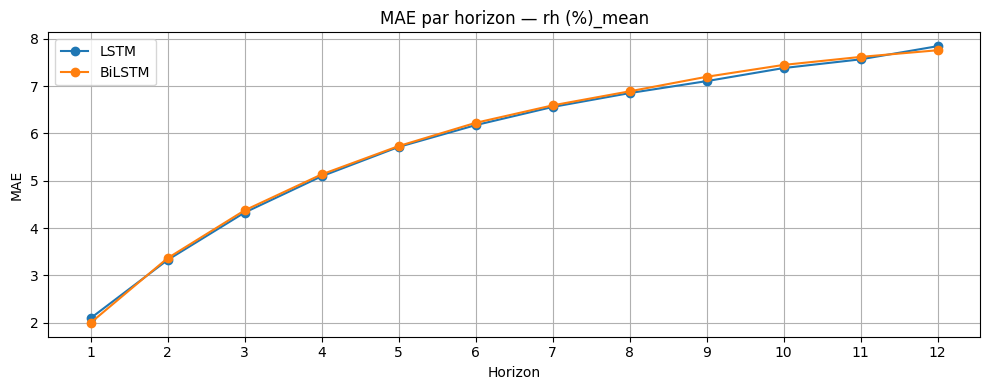

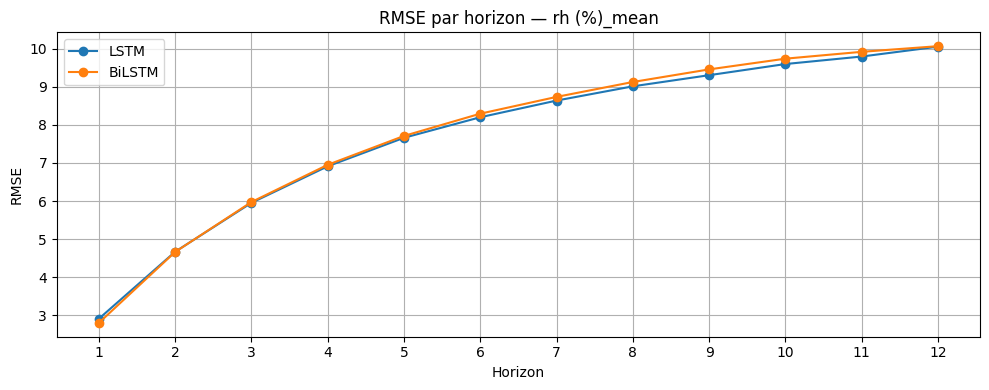

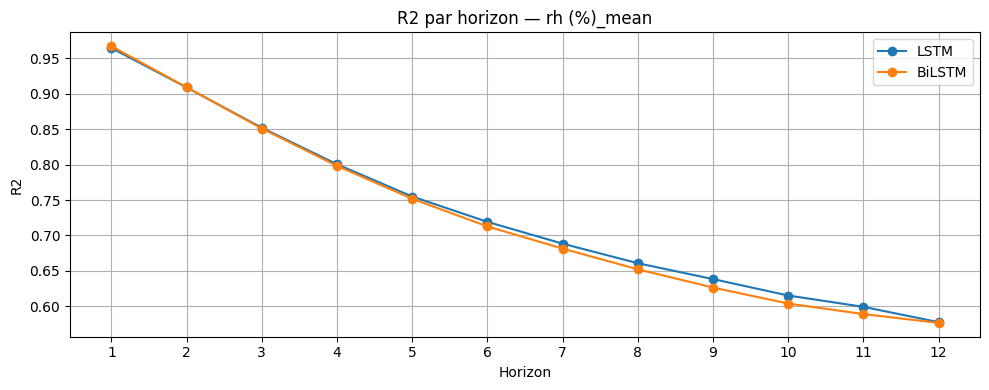

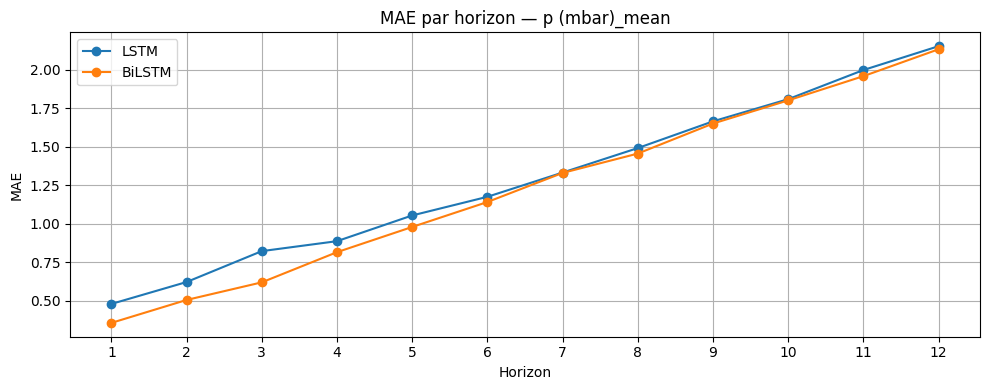

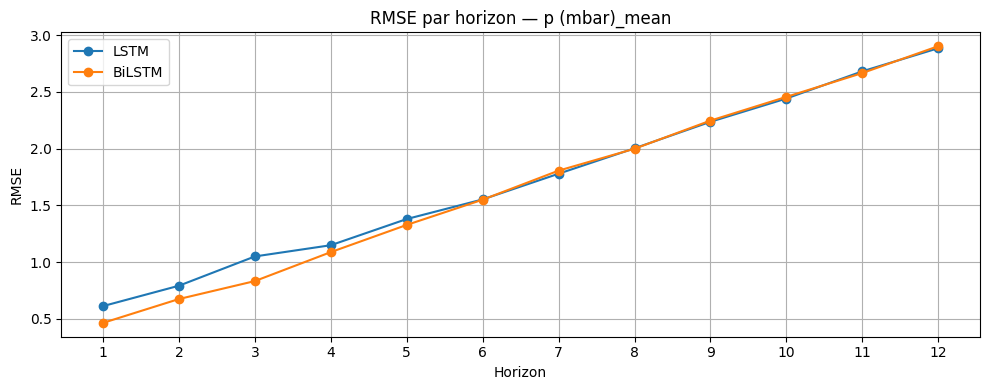

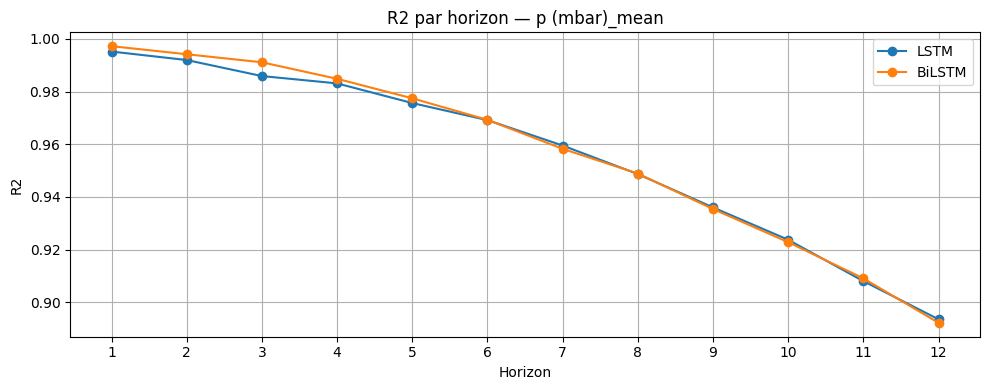

In [19]:
# VISUALISATION DES MÉTRIQUES PAR HORIZON
def plot_metric_by_horizon(df_scores, variable_name, metric_name):
    plt.figure(figsize=(10, 4))
    for model_name in df_scores['Model'].unique():
        sub = df_scores[
            (df_scores['Model'] == model_name) &
            (df_scores['Variable'] == variable_name)
        ]
        plt.plot(sub['Horizon'], sub[metric_name], marker='o', label=model_name)
    plt.title(f'{metric_name} par horizon — {variable_name}')
    plt.xlabel('Horizon')
    plt.ylabel(metric_name)
    plt.xticks(range(1, horizon + 1))
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

for var in target_cols:
    for metric in ['MAE', 'RMSE', 'R2']:
        plot_metric_by_horizon(df_scores, var, metric)

### Interprétation des courbes métriques par horizon

- **MAE et RMSE augmentent** régulièrement avec l'horizon : plus on prédit loin dans le futur, plus l'erreur s'accumule.
- **R² diminue** avec l'horizon : le modèle explique moins bien la variance pour les prédictions lointaines.
- **Température (T) et humidité (rh)**  : les deux modèles se comportent de façon comparable, avec une légère supériorité du LSTM sur les horizons longs.
- **Pression (p)** : les erreurs augmentent de façon stable par horizon. Le BiLSM performe mieux sur les premiers horizons de cette variable.

---
## Q15 — Réel vs Prédit sur un échantillon de test (tous les horizons)

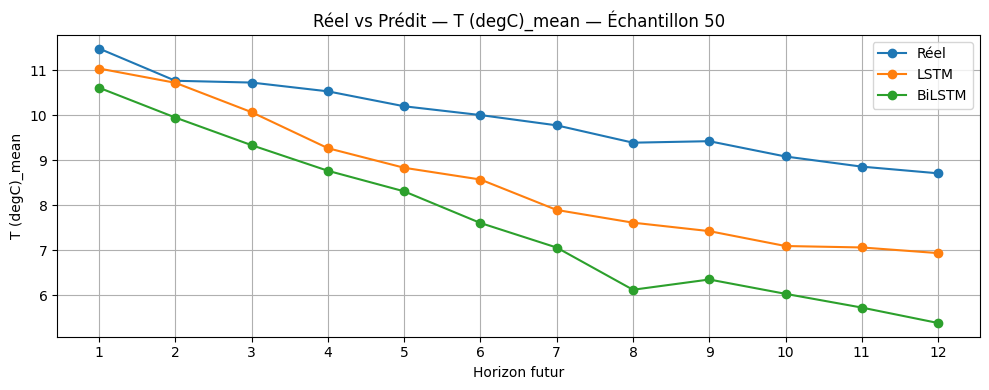

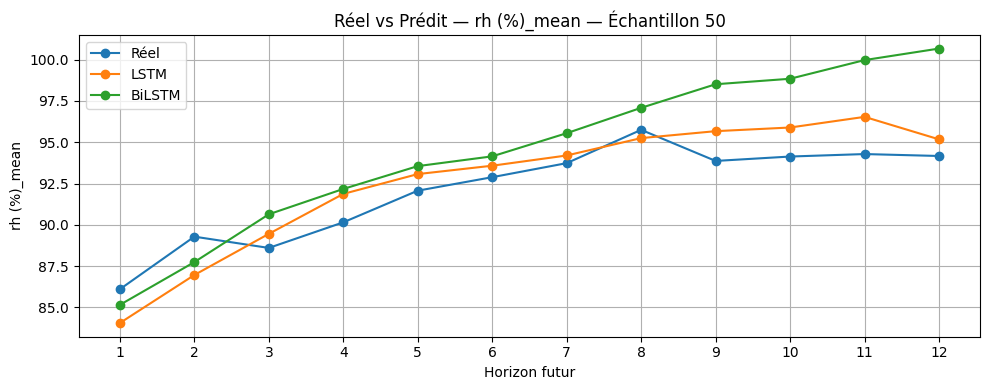

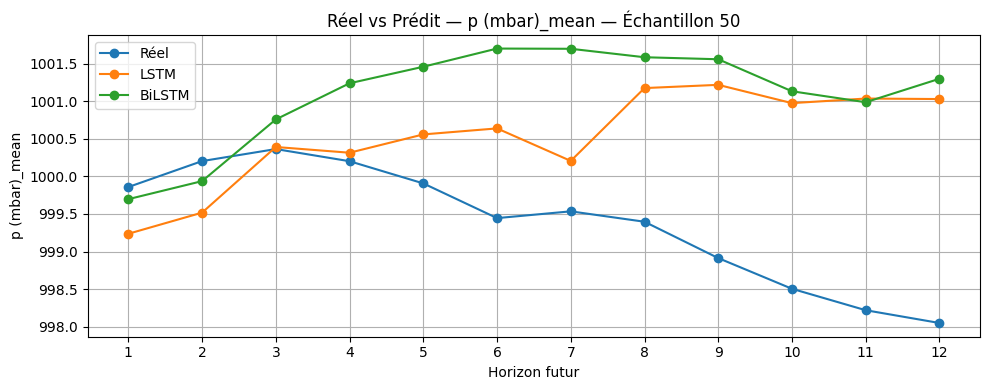

In [20]:
# ── RÉEL vs PRÉDIT SUR UN ÉCHANTILLON DE TEST ─────────────────────────────
sample_idx = 50  # choix de l'échantillon

def plot_forecast_comparison(y_true, y_pred_lstm, y_pred_bilstm,
                              target_cols, sample_idx):
    horizons = np.arange(1, y_true.shape[1] + 1)
    for j, var_name in enumerate(target_cols):
        plt.figure(figsize=(10, 4))
        plt.plot(horizons, y_true[sample_idx, :, j],
                 marker='o', label='Réel')
        plt.plot(horizons, y_pred_lstm[sample_idx, :, j],
                 marker='o', label='LSTM')
        plt.plot(horizons, y_pred_bilstm[sample_idx, :, j],
                 marker='o', label='BiLSTM')
        plt.title(f'Réel vs Prédit — {var_name} — Échantillon {sample_idx}')
        plt.xlabel('Horizon futur')
        plt.ylabel(var_name)
        plt.xticks(horizons)
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_forecast_comparison(
    y_test_inv, y_pred_lstm_inv, y_pred_bilstm_inv,
    target_cols, sample_idx
)

### Commentaire des écarts observés

- **Température moyenne** : les deux modèles suivent bien la tendance générale. Le LSTM semble légèrement mieux suivre la courbe réelle par rapport au BiLSTM, mais les deux modèles restent au dessous de la courbe réelle (sous-estimation).
- **Humidité moyenne** :  les deux modèles capturent bien la tendance croissante. Le LSTM semble globalement être plus précis surtout à partir de l'horizon 9.
- **Pression moyenne** : les deux modèles ne suivent pas parfaitement la tendance générale. Ils surestiment les valeurs réelles à partir de l'horizon 5.

---
## Q16 — Comparaison sur plusieurs échantillons à un horizon fixé

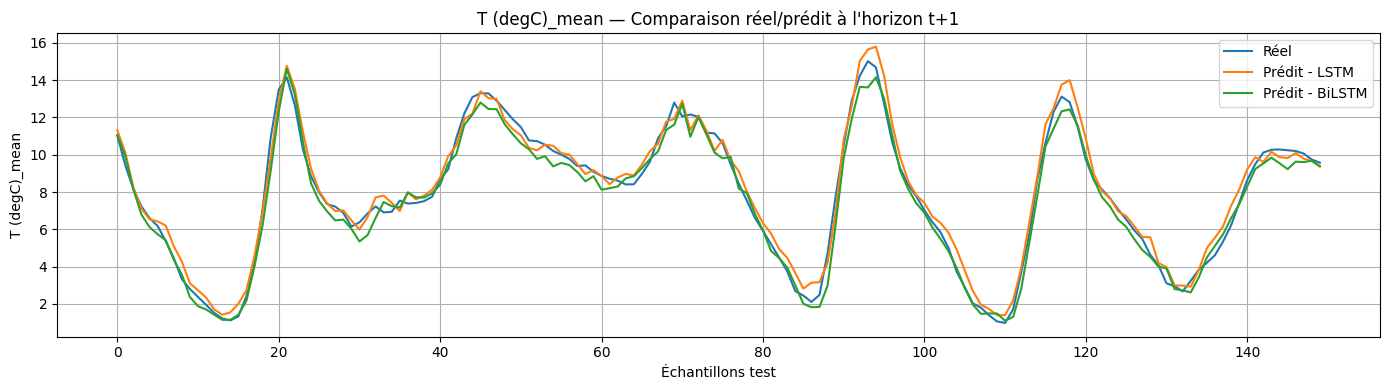

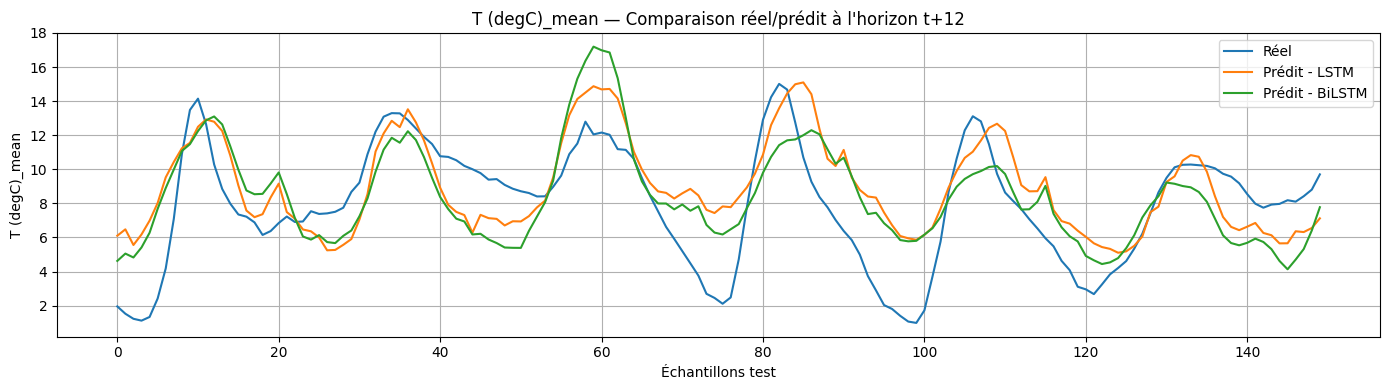

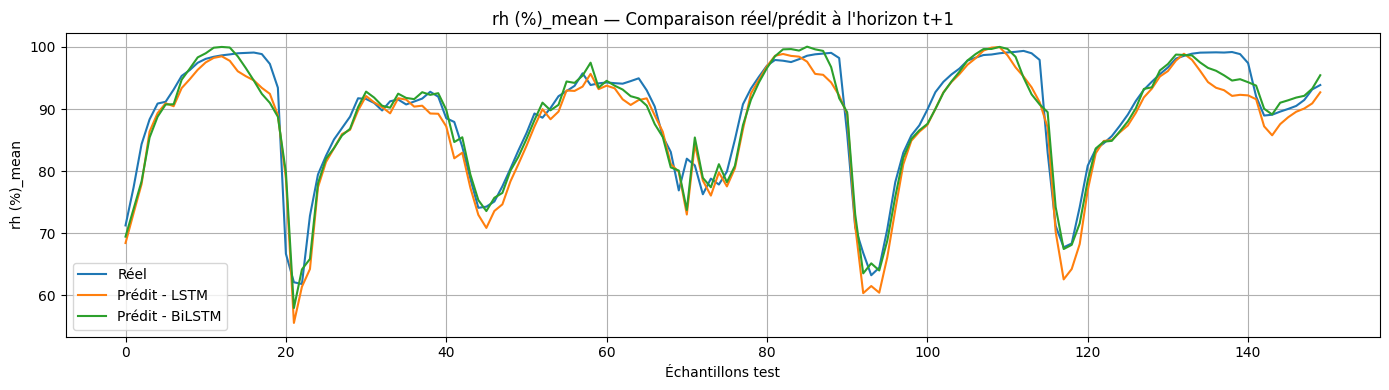

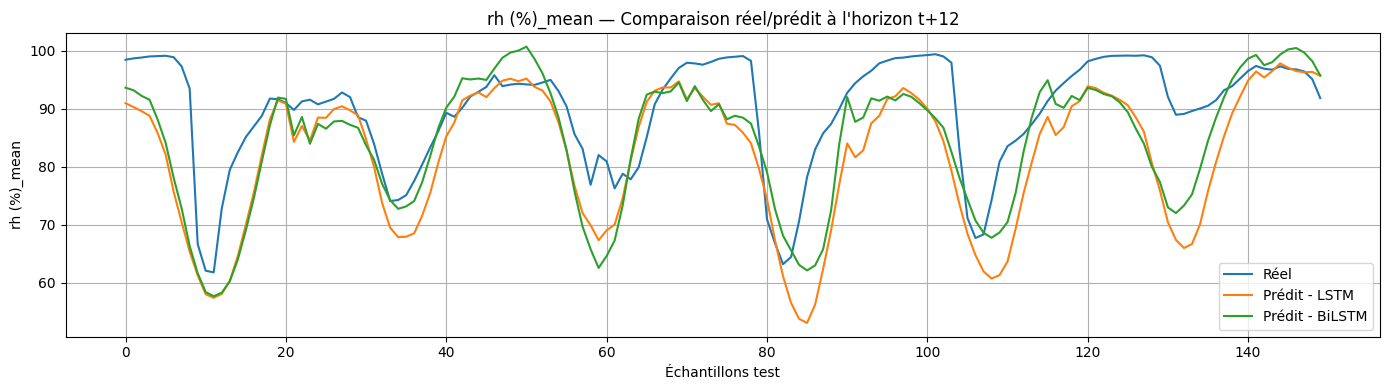

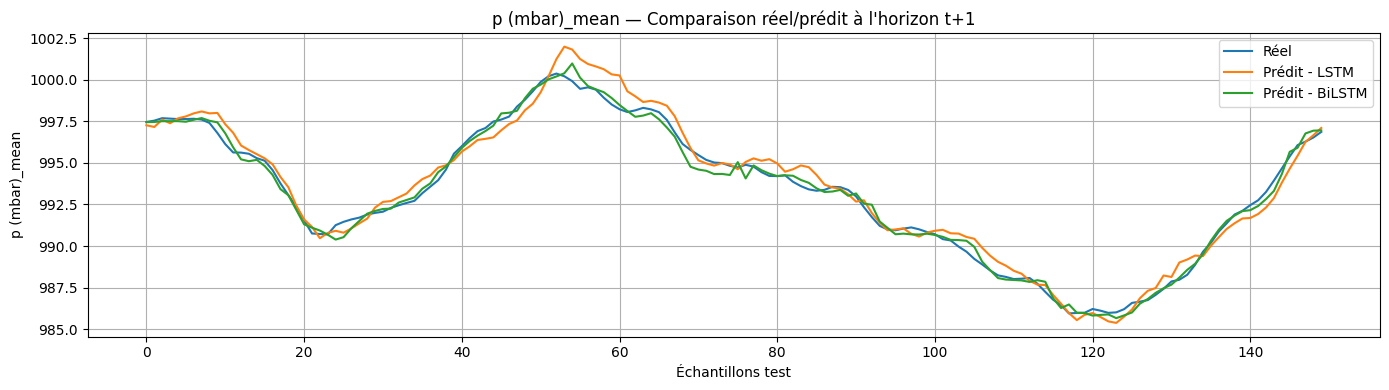

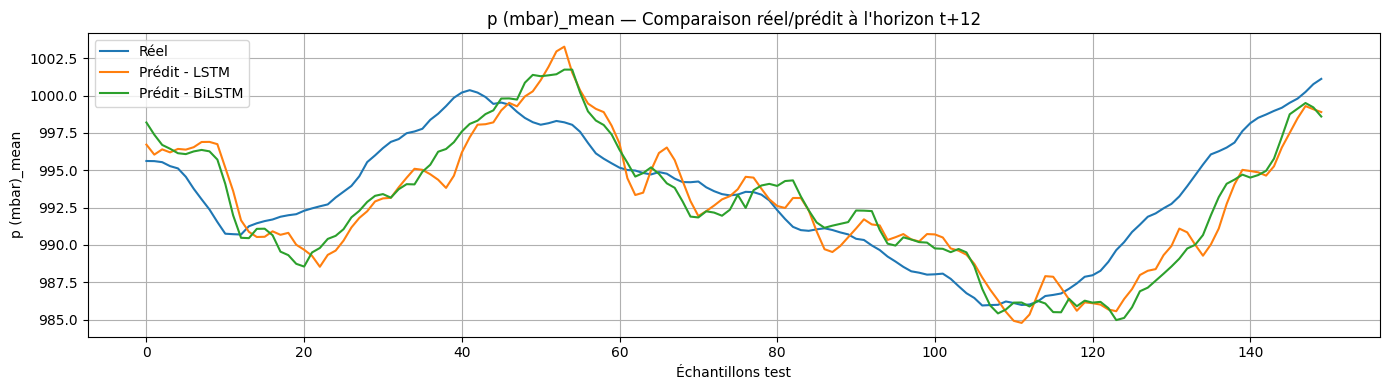

In [21]:
# ── COMPARAISON À UN HORIZON FIXÉ ─────────────────────────────────────────
def plot_fixed_horizon_over_samples(y_true, y_pred_lstm, y_pred_bilstm,
                                     variable_idx, variable_name,
                                     selected_horizon, n_points=150):
    h = selected_horizon - 1  # index 0-based
    plt.figure(figsize=(14, 4))
    plt.plot(y_true[:n_points, h, variable_idx],
             label='Réel')
    plt.plot(y_pred_lstm[:n_points, h, variable_idx],
             label='Prédit - LSTM')
    plt.plot(y_pred_bilstm[:n_points, h, variable_idx],
             label='Prédit - BiLSTM')
    plt.title(f'{variable_name} — Comparaison réel/prédit à l\'horizon t+{selected_horizon}')
    plt.xlabel('Échantillons test')
    plt.ylabel(variable_name)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Horizon t+1 et t+12 pour chaque variable
for j, var in enumerate(target_cols):
    plot_fixed_horizon_over_samples(
        y_test_inv, y_pred_lstm_inv, y_pred_bilstm_inv,
        j, var, selected_horizon=1, n_points=150
    )
    plot_fixed_horizon_over_samples(
        y_test_inv, y_pred_lstm_inv, y_pred_bilstm_inv,
        j, var, selected_horizon=12, n_points=150
    )

 **Stabilité globale** : les prédictions restent cohérentes sur l'ensemble des échantillons, sans dérives importantes, ce qui confirme la robustesse des deux modèles.

---
## Q17 — Identification du meilleur modèle par variable cible et conclusions

In [22]:
# ── TABLEAU FINAL : meilleur modèle par variable et par horizon ────────────
pivot_rmse_full = df_scores.pivot_table(
    index=['Horizon', 'Variable'],
    columns='Model',
    values='RMSE'
).round(4)

pivot_rmse_full['Meilleur modèle'] = pivot_rmse_full.idxmin(axis=1)
print('Meilleur modèle (RMSE le plus faible) par Horizon et Variable :')
print(pivot_rmse_full.to_string())

Meilleur modèle (RMSE le plus faible) par Horizon et Variable :
Model                   BiLSTM     LSTM Meilleur modèle
Horizon Variable                                       
1       T (degC)_mean   0.6783   0.5782            LSTM
        p (mbar)_mean   0.4641   0.6122          BiLSTM
        rh (%)_mean     2.8010   2.9095          BiLSTM
2       T (degC)_mean   0.9819   0.9653            LSTM
        p (mbar)_mean   0.6745   0.7918          BiLSTM
        rh (%)_mean     4.6629   4.6684          BiLSTM
3       T (degC)_mean   1.2797   1.2697            LSTM
        p (mbar)_mean   0.8329   1.0501          BiLSTM
        rh (%)_mean     5.9738   5.9528            LSTM
4       T (degC)_mean   1.5138   1.5099            LSTM
        p (mbar)_mean   1.0882   1.1490          BiLSTM
        rh (%)_mean     6.9513   6.9124            LSTM
5       T (degC)_mean   1.7251   1.7079            LSTM
        p (mbar)_mean   1.3280   1.3799          BiLSTM
        rh (%)_mean     7.7094   7.6603 

### Conclusions

**Résultats :**

| Variable | Meilleur modèle global |
|----------|----------------------|
| T (degC) | **LSTM**             |
| rh (%)   | **LSTM** (à partir de h=3) |
| p (mbar) | **BiLSTM** (horizons courts/moyens) |
**Impact de l'architecture :**
- Le **BiLSTM** traite la séquence dans les deux sens (forward + backward), ce qui lui donne un avantage sur les horizons courts où le contexte récent ET le contexte passé sont utiles.
- Le **LSTM** reste compétitif sur les horizons longs, car il est plus simple et moins sujet au sur-apprentissage.

**Impact de l'horizon :**
- La dégradation des performances avec l'horizon est **inévitable** pour toutes les variables cibles.
- La pression moyenne reste la variable la plus stable car elle évolue lentement (effet du lissage par la moyenne).
- L'humidité moyenne est la plus difficile à prédire : ses variations sont moins structurées.

---
# PARTIE II — Questions d'analyse

## Q1 — Pourquoi utilise-t-on deux scalers différents pour X et Y ?

On utilise deux scalers distincts (**scaler_X** et **scaler_y**) car X et Y ont des distributions différentes.

- **scaler_X** est ajusté sur les 18 variables d'entrée. Il apprend les min/max de ces 18 distributions.
- **scaler_y** est ajusté uniquement sur les 3 variables cibles. Il apprend les min/max propres à T, rh et p.

Si un seul scaler était utilisé pour X et Y ensemble, l'inverse transformation ne pourrait pas distinguer les plages de valeurs des features de celles des cibles. On obtiendrait des valeurs dénormalisées incorrectes, rendant l'évaluation impossible.

## Q2 — Pourquoi la sortie Y doit-elle être aplatie avant l'entraînement ?

La couche **Dense** de Keras ne peut produire qu'un **vecteur 1D** pour chaque exemple. Elle ne peut pas directement générer une matrice `(horizon, n_targets)`.

Dans notre cas : `horizon=12` et `n_targets=3`, donc la sortie réelle serait `(12, 3)` — une matrice 2D.

On doit donc **aplatir** cette matrice en un vecteur de taille `12 × 3 = 36`, compatible avec `Dense(36)`. Après prédiction, on reconstitue la structure `(n, 12, 3)` avec un **reshape**.

| Cas | Shape réelle | Shape Dense | Transformation |
|-----|-------------|-------------|----------------|
| Univarié | (n, 12) | (n, 12) | Aucune |
| Multivarié | (n, 12, 3) | (n, 36) | Flatten |

## Q3 — La prédiction des valeurs moyennes est-elle plus stable que celle des valeurs extrêmes ?

**Oui, la prédiction des moyennes est plus stable**, pour plusieurs raisons :

1. **Lissage des fluctuations** : la moyenne atténue les pics et les creux ponctuels, rendant la série plus régulière et plus facile à modéliser.
2. **Bruit réduit** : les valeurs extrêmes (max/min) capturent des événements rares et moins prévisibles par nature.
3. **Autocorrélation plus forte** : les moyennes horaires présentent des dépendances temporelles plus lisibles (cycles journaliers bien marqués).


## Q4 — Pourquoi évaluer par horizon et par variable, et non globalement ?

Une évaluation **globale unique** masquerait des informations essentielles :

- **Par horizon** : les performances se dégradent naturellement avec l'horizon. Une moyenne globale mélangerait les bons résultats à t+1 avec les mauvais à t+12, donnant une image faussée.
- **Par variable** : chaque variable a ses propres unités et dynamiques. La pression (mbar) a une variance différente de l'humidité (%). Un RMSE global serait dominé par la variable à plus grande variance.

L'évaluation fine permet de répondre à des questions concrètes : *Le modèle est-il fiable pour prédire la température à 6h ? La pression à 12h ?*